# MDSI Skills Map — Day 1 Pipeline Prototype (Student C)

Student C's blocks: 4 (pipeline), 6 (gap chart, key figure), 7 (course table).

Skills come from an ESCO dictionary lookup, then TF-IDF fuzzy matching catches
near-misses that lookup drops, comparing one sample resume against one real
"Data Scientist, Sydney" job posting.

Scope is small on purpose: one resume vs. one job ad already gives two real figures
from real data, with sample size noted. LinkedIn-scale data, embeddings, and the web
app are AT2B, not this stage.

## 1. Setup

In [12]:
import re
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

plt.rcParams["font.family"] = "Avenir Next"   # matches the team's clean sans-serif style sheet

TEAL = "#0F6E68"     # "have" / market-aligned, matches team style sheet
COPPER = "#B8541F"   # "missing" / gap
SURFACE = "#FFFFFF"
SURFACE_2 = "#EEF2F0"   # tile background behind grouped items
LINE = "#D6DDDA"        # hairline dividers
TEXT = "#1B2530"        # body ink
MUTED = "#5C6974"       # captions, subtext
ACCENT_SOFT = "#DCEFEC" # teal tint
GAP_SOFT = "#F6E3D6"    # copper tint


## 2. ESCO skills dictionary (real data, pulled live from the ESCO API)

Source: `ec.europa.eu/esco/api` — essential + optional skills linked to the ESCO
**"data scientist"** occupation concept, plus a few individually looked-up ESCO skill
concepts (Python, SQL, R, NLP, etc.) that aren't tagged onto that specific occupation
profile but are core to the role in practice.

That gap is itself a small piece of evidence for the poster's problem statement: ESCO's
standardised vocabulary and the industry's job-ad vocabulary don't fully line up
(e.g. "deep learning" and "generative AI" — both in the job ad below — have no clean
ESCO skill match at all).

In [13]:
DS_OCCUPATION_URI = "http://data.europa.eu/esco/occupation/258e46f9-0075-4a2e-adae-1ff0477e0f30"

FALLBACK_ESSENTIAL = [
    "data mining", "build recommender systems", "interpret current data",
    "visual presentation techniques", "resource description framework query language",
    "develop data processing applications", "design database scheme",
    "report analysis results", "execute analytical mathematical calculations",
    "deliver visual presentation of data", "statistics", "information categorisation",
    "implement data quality processes", "collect ICT data", "online analytical processing",
]
FALLBACK_OPTIONAL = [
    "LDAP", "MDX", "integrate ICT data", "manage data", "create data models",
    "business intelligence", "SPARQL", "data quality assessment",
    "manage ICT data classification", "manage ICT data architecture",
    "unstructured data", "N1QL", "XQuery", "LINQ", "define data quality criteria",
]

try:
    r = requests.get(
        "https://ec.europa.eu/esco/api/resource/occupation",
        params={"uri": DS_OCCUPATION_URI, "language": "en"},
        timeout=10,
    )
    r.raise_for_status()
    occ = r.json()
    essential = [s["title"] for s in occ["_links"].get("hasEssentialSkill", [])]
    optional = [s["title"] for s in occ["_links"].get("hasOptionalSkill", [])]
    print("Pulled live from ESCO API.")
except Exception as e:
    print(f"ESCO API unreachable ({e}); using cached copy from Day 1.")
    essential, optional = FALLBACK_ESSENTIAL, FALLBACK_OPTIONAL

# A few extra ESCO skill concepts, individually looked up via the same API
# (esco.ec.europa.eu/api/search?text=...&type=skill), for terms core to the
# role that the occupation-level relation list above doesn't happen to include.
extra_esco_lookups = [
    "Python (computer programming)", "SQL", "R", "natural language processing",
    "utilise machine learning", "analyse big data", "build predictive models",
    "principles of artificial intelligence", "cloud technologies",
    "visual presentation techniques", "prepare visual data",
]

esco_dictionary = sorted(set(essential) | set(optional) | set(extra_esco_lookups))
print(f"\nESCO dictionary size: {len(esco_dictionary)} skills "
      f"(essential={len(essential)}, optional={len(optional)}, "
      f"manually looked up={len(extra_esco_lookups)})")


Pulled live from ESCO API.

ESCO dictionary size: 49 skills (essential=23, optional=16, manually looked up=11)


In [14]:
# Synonym map so common surface variants (e.g. "AI", "predictive modelling") still
# match without a literal substring hit
SYNONYMS = {
    "machine learning": "utilise machine learning",
    "predictive modelling": "build predictive models",
    "predictive models": "build predictive models",
    "data visualization": "visual presentation techniques",
    "data visualisation": "visual presentation techniques",
    "big data": "analyse big data",
    "ai": "principles of artificial intelligence",
    "artificial intelligence": "principles of artificial intelligence",
    "python": "Python (computer programming)",
}


## 3. Input texts

Job posting: real "Data Scientist – Python, SQL" listing, Sydney CBD, Robert Walters
Australia (scraped 23 Sept 2026) — genuine market text, not a mock-up.

Resume: a synthetic template for an early-career MDSI-style candidate, not a real
person's.

In [15]:
job_text = """Data Scientist - Python, SQL
Robert Walters Australia
Sydney CBD, Hybrid Working Arrangements
Source: robertwalters.com.au, Job Reference PLAIZ0-9596BEC2

Overview
Join a team of industry experts where you will play a pivotal role in advancing the
firm's financial security measures. You will leverage your strong Python and SQL
skills, along with your deep understanding of the latest trends in deep learning and
generative AI, to build and deploy innovative AI solutions.

Key Responsibilities
- Develop and implement predictive models and machine learning algorithms to solve
  complex business problems.
- Analyze large datasets to uncover insights and trends that drive strategic
  decision-making.
- Stay current with advancements in deep learning, generative AI, and other AI
  technologies, and apply this knowledge to enhance our AI capabilities.
- Collaborate with cross-functional teams to integrate AI solutions into existing
  systems and processes.
- Continuously improve data science methodologies and processes to ensure
  high-quality outcomes.

Key Requirements
- 3-5+ years of experience in data science, with a strong track record of delivering
  successful AI solutions.
- Strong programming experience with Python and SQL.
- In-depth knowledge of deep learning, Generative AI, and other advanced AI
  technologies; LLM, GenAI etc.
- Experience in building and deploying AI models and solutions.
- Strong analytical and problem-solving skills.

Location: Sydney CBD. Workplace Type: Hybrid. Experience Level: Associate.
"""

resume_text = """SAMPLE RESUME (synthetic template, MDSI-style early-career candidate)

Summary
Master of Data Science and Innovation student with a background in business
analysis. Comfortable working with structured business data, building dashboards,
and communicating findings to non-technical stakeholders. Looking to move into a
data scientist role.

Skills
- SQL: writing queries, joins, and aggregations across relational databases
- Python: pandas and matplotlib for data cleaning, exploration, and visualisation
- Data visualisation: building dashboards and charts in Power BI and Excel
- Statistics: descriptive statistics, hypothesis testing basics
- Communication: presenting analysis to business stakeholders

Experience
Business Intelligence Analyst, retail e-commerce company (2 years)
- Built recurring sales and fraud-monitoring reports using SQL and Power BI
- Queried transactional databases to investigate customer support cases
- Presented findings to operations and payments teams

Education
Master of Data Science and Innovation (in progress), University of Technology Sydney
Bachelor's degree, Business/Commerce
"""

print(f"Job posting word count: {len(job_text.split())}")
print(f"Sample resume word count: {len(resume_text.split())}")


Job posting word count: 218
Sample resume word count: 145


## 4. Dictionary extraction (exact + synonym match)

In [16]:
def normalise(text):
    return re.sub(r"\s+", " ", text.lower())


def dictionary_extract(text, dictionary):
    t = normalise(text)
    found = set()
    for skill in dictionary:
        pattern = r"\b" + re.escape(skill.lower()) + r"\b"
        if re.search(pattern, t):
            found.add(skill)
    for surface, canonical in SYNONYMS.items():
        if re.search(r"\b" + re.escape(surface) + r"\b", t) and canonical in dictionary:
            found.add(canonical)
    return found


job_skills_exact = dictionary_extract(job_text, esco_dictionary)
resume_skills_exact = dictionary_extract(resume_text, esco_dictionary)

print("Job skills (exact dictionary match):", sorted(job_skills_exact))
print("Resume skills (exact dictionary match):", sorted(resume_skills_exact))


Job skills (exact dictionary match): ['Python (computer programming)', 'SQL', 'build predictive models', 'principles of artificial intelligence', 'utilise machine learning']
Resume skills (exact dictionary match): ['Python (computer programming)', 'SQL', 'business intelligence', 'statistics', 'visual presentation techniques']


## 5. TF-IDF fuzzy matching

Exact substring matching misses paraphrases ("build and deploy AI models" vs. ESCO's
"build predictive models"). This step compares word n-grams from each text against every
ESCO skill label using character-level TF-IDF + cosine similarity, catching near-misses
the dictionary lookup drops.

Char n-gram TF-IDF is noisy — it can match on shared substrings rather than real meaning,
which is why AT2B moves to embeddings instead. Threshold below is set high (0.55) to keep
obvious false positives down for this prototype.

In [17]:
def tfidf_fuzzy_match(text, dictionary, threshold=0.55):
    words = re.findall(r"[a-zA-Z][a-zA-Z\-]+", text.lower())
    ngrams = set()
    for n in (1, 2, 3, 4):
        for i in range(len(words) - n + 1):
            ngrams.add(" ".join(words[i : i + n]))
    ngrams = list(ngrams)
    if not ngrams:
        return set()

    corpus = ngrams + [s.lower() for s in dictionary]
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))
    tfidf = vec.fit_transform(corpus)
    ngram_vecs = tfidf[: len(ngrams)]
    skill_vecs = tfidf[len(ngrams) :]

    sims = cosine_similarity(ngram_vecs, skill_vecs)
    matched = set()
    for j, skill in enumerate(dictionary):
        if sims[:, j].max() >= threshold:
            matched.add(skill)
    return matched


job_skills_fuzzy = tfidf_fuzzy_match(job_text, esco_dictionary)
resume_skills_fuzzy = tfidf_fuzzy_match(resume_text, esco_dictionary)

job_skills = job_skills_exact | job_skills_fuzzy
resume_skills = resume_skills_exact | resume_skills_fuzzy

print("Job skills (exact + fuzzy):", sorted(job_skills))
print("Resume skills (exact + fuzzy):", sorted(resume_skills))


Job skills (exact + fuzzy): ['Python (computer programming)', 'SQL', 'build predictive models', 'business intelligence', 'cloud technologies', 'create data models', 'data models', 'execute analytical mathematical calculations', 'implement data quality processes', 'integrate ICT data', 'interpret current data', 'online analytical processing', 'principles of artificial intelligence', 'utilise machine learning']
Resume skills (exact + fuzzy): ['Python (computer programming)', 'SQL', 'business intelligence', 'handle data samples', 'statistics', 'unstructured data', 'visual presentation techniques']


## 6. Gap analysis

In [18]:
matched = sorted(job_skills & resume_skills)
missing = sorted(job_skills - resume_skills)
extra = sorted(resume_skills - job_skills)

print(f"n = {len(job_skills)} distinct skills detected as required by this job posting")
print(f"\nMatched ({len(matched)}):", matched)
print(f"\nMissing / gap ({len(missing)}):", missing)
print(f"\nResume-only, not required by this job ({len(extra)}):", extra)


n = 14 distinct skills detected as required by this job posting

Matched (3): ['Python (computer programming)', 'SQL', 'business intelligence']

Missing / gap (11): ['build predictive models', 'cloud technologies', 'create data models', 'data models', 'execute analytical mathematical calculations', 'implement data quality processes', 'integrate ICT data', 'interpret current data', 'online analytical processing', 'principles of artificial intelligence', 'utilise machine learning']

Resume-only, not required by this job (4): ['handle data samples', 'statistics', 'unstructured data', 'visual presentation techniques']


## 6b. Market demand baseline (real, n = 3,204)

The single job ad above only says a skill is required or not — it can't say *how commonly*
required, so a bar length would have carried no information. B's Seek Australia corpus
(`jobs_au_seek_datascientist_2019-2022.csv`, the same file behind block 5's top-15 chart)
fixes that: it's 3,204 real Data Scientist ads, so the % of them mentioning each skill is a
genuine demand level. That percentage becomes the gap chart's horizontal axis below —
skill vs. demand %, bar colour still showing whether the sample resume covers it.

In [19]:
SEEK_PATH = "data-eda/data/raw/jobs_au_seek_datascientist_2019-2022.csv"  # sibling of this notebook's folder
seek_ads = pd.read_csv(SEEK_PATH)
descriptions_lower = seek_ads["description"].str.lower()
n_ads = len(seek_ads)


def corpus_demand(texts_lower, dictionary, synonyms):
    demand_mask = {}
    for skill in dictionary:
        pattern = r"\b" + re.escape(skill.lower()) + r"\b"
        demand_mask[skill] = texts_lower.str.contains(pattern, regex=True, na=False)
    for surface, canonical in synonyms.items():
        if canonical in dictionary:
            pattern = r"\b" + re.escape(surface) + r"\b"
            demand_mask[canonical] |= texts_lower.str.contains(pattern, regex=True, na=False)
    return {skill: mask.mean() for skill, mask in demand_mask.items()}


skill_demand = corpus_demand(descriptions_lower, esco_dictionary, SYNONYMS)

print(f"Market demand computed over n = {n_ads} real Seek Australia Data Scientist ads (2019-2022).")
print("Demand for this job's required skills:")
for skill in sorted(job_skills, key=lambda s: -skill_demand.get(s, 0)):
    print(f"  {skill_demand.get(skill, 0):5.1%}  {skill}")


Market demand computed over n = 3204 real Seek Australia Data Scientist ads (2019-2022).
Demand for this job's required skills:
  82.8%  Python (computer programming)
  71.2%  utilise machine learning
  56.8%  SQL
  24.9%  build predictive models
  22.5%  principles of artificial intelligence
   6.4%  business intelligence
   2.9%  data models
   2.0%  cloud technologies
   0.0%  create data models
   0.0%  execute analytical mathematical calculations
   0.0%  integrate ICT data
   0.0%  online analytical processing
   0.0%  implement data quality processes
   0.0%  interpret current data


## 7. Gap chart — **poster block 6, key figure**

Horizontal bar chart: vertical axis is the skill, horizontal axis is real market demand %
(from the n = 3,204 Seek corpus above), bar colour shows whether the sample resume covers
it. Same teal/copper style-sheet colours, no legend, direct value labels instead of an
x-axis. Exported at 300dpi for the A0 poster.

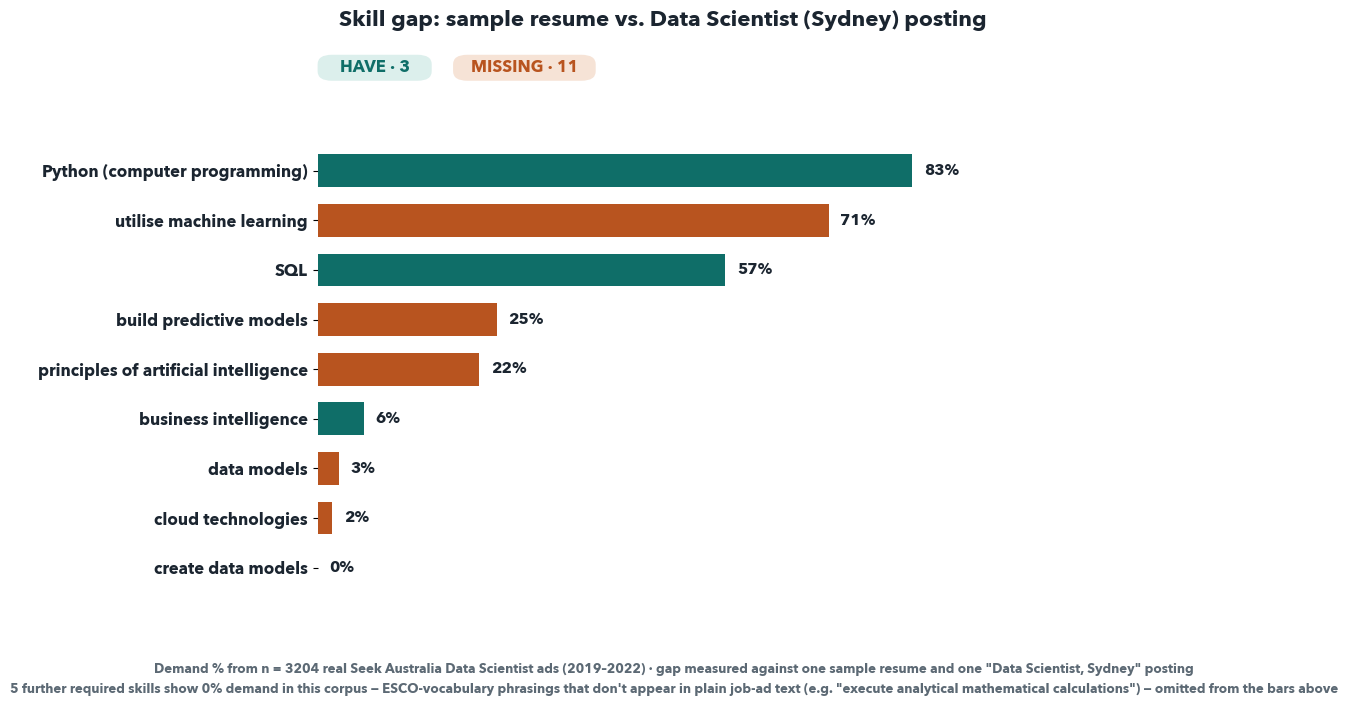

Saved gap_chart.png at 300dpi — drop this straight into the poster (block 6).


In [20]:
zero_demand_missing = [s for s in missing if skill_demand.get(s, 0) == 0]
gap_skills = sorted((s for s in job_skills if s not in zero_demand_missing),
                     key=lambda s: skill_demand.get(s, 0))
demand_pct = [skill_demand.get(s, 0) * 100 for s in gap_skills]
bar_colors = [TEAL if s in matched else COPPER for s in gap_skills]
y_pos = np.arange(len(gap_skills))

fig, ax = plt.subplots(figsize=(9.2, max(3.8, 0.46 * len(gap_skills) + 2.0)))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

ax.barh(y_pos, demand_pct, color=bar_colors, height=0.66, zorder=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(gap_skills, fontsize=12, color=TEXT)
ax.set_xticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

x_max = max(demand_pct) if demand_pct else 1
for y, pct in zip(y_pos, demand_pct):
    ax.text(pct + x_max * 0.02, y, f"{pct:.0f}%", va="center", fontsize=11.5,
            fontweight="bold", color=TEXT, zorder=3)
ax.set_xlim(0, x_max * 1.2)

pill_y, pill_h = 1.11, 0.055
ax.add_patch(mpatches.FancyBboxPatch((0.0, pill_y), 0.16, pill_h,
             boxstyle="round,pad=0.0,rounding_size=0.02", linewidth=0,
             facecolor=ACCENT_SOFT, transform=ax.transAxes, clip_on=False))
ax.text(0.08, pill_y + pill_h / 2, f"HAVE · {len(matched)}", ha="center", va="center",
        fontsize=12, fontweight="bold", color=TEAL, transform=ax.transAxes)
ax.add_patch(mpatches.FancyBboxPatch((0.19, pill_y), 0.20, pill_h,
             boxstyle="round,pad=0.0,rounding_size=0.02", linewidth=0,
             facecolor=GAP_SOFT, transform=ax.transAxes, clip_on=False))
ax.text(0.29, pill_y + pill_h / 2, f"MISSING · {len(missing)}", ha="center", va="center",
        fontsize=12, fontweight="bold", color=COPPER, transform=ax.transAxes)

fig.suptitle("Skill gap: sample resume vs. Data Scientist (Sydney) posting",
             fontsize=16, fontweight="bold", color=TEXT, y=1.08)
caption = (f"Demand % from n = {n_ads} real Seek Australia Data Scientist ads (2019–2022) · "
           f"gap measured against one sample resume and one \"Data Scientist, Sydney\" posting")
if zero_demand_missing:
    caption += (f"\n{len(zero_demand_missing)} further required skills show 0% demand in this "
                f"corpus — ESCO-vocabulary phrasings that don't appear in plain job-ad text "
                f"(e.g. \"{zero_demand_missing[0]}\") — omitted from the bars above")
ax.text(0.5, -0.12, caption, ha="center", va="top", fontsize=9.5, color=MUTED,
        transform=ax.transAxes, linespacing=1.7)

plt.savefig("gap_chart.png", dpi=300, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print("Saved gap_chart.png at 300dpi — drop this straight into the poster (block 6).")


## 8. Course-matching table — **poster block 7**

Real MDSI/UTS subjects from B's actual handbook scrape (`uts_subjects_2026.csv`, 70 subjects,
real learning outcomes), keyword-matched against each missing skill — the same technique
B used for the AWS/cloud worked example in their own handoff. Worth a manual spot-check
before this goes on the poster, since it's keyword matching over subject text, not a
semantic match.

In [21]:
UTS_SUBJECTS_PATH = "data-eda/data/raw/uts_subjects_2026.csv"
uts_subjects = pd.read_csv(UTS_SUBJECTS_PATH)
uts_subjects["search_text"] = (
    uts_subjects["subject_name"].fillna("") + " " +
    uts_subjects["description"].fillna("") + " " +
    uts_subjects["topics"].fillna("") + " " +
    uts_subjects["learning_outcomes"].fillna("")
).str.lower()

SKILL_KEYWORDS = {
    "utilise machine learning": ["machine learning"],
    "build predictive models": ["predictive model", "machine learning"],
    "principles of artificial intelligence": ["artificial intelligence"],
    "cloud technologies": ["cloud"],
    "data models": ["data model"],
    "create data models": ["data model"],
    "integrate ict data": ["data integration", "data engineering", "etl"],
    "interpret current data": ["data analysis", "data analytics"],
    "online analytical processing": ["data warehouse", "business intelligence"],
    "implement data quality processes": ["data quality", "data governance"],
    "execute analytical mathematical calculations": ["statistic", "quantitative method"],
    "visual presentation techniques": ["visualisation", "visualization"],
    "prepare visual data": ["visualisation", "visualization"],
    "statistics": ["statistic"],
    "natural language processing": ["natural language processing", "text data"],
    "data mining": ["data mining"],
}


def best_subject_for(skill):
    keywords = SKILL_KEYWORDS.get(skill.lower(), [skill.lower()])
    hit_counts = uts_subjects["search_text"].apply(lambda t: sum(t.count(k) for k in keywords))
    if hit_counts.max() == 0:
        return None
    row = uts_subjects.loc[hit_counts.idxmax()]
    outcomes = [o.strip() for o in re.split(r"SLO\d+:\s*", row["learning_outcomes"]) if o.strip()]
    matching_outcome = next((o for o in outcomes if any(k in o.lower() for k in keywords)),
                             outcomes[0] if outcomes else "")
    return f"{row['subject_code']} {row['subject_name']}", matching_outcome


course_rows = []
for skill in missing:
    result = best_subject_for(skill)
    if result and len(course_rows) < 5:
        subj, outcome = result
        course_rows.append((skill, subj, outcome))

course_table = pd.DataFrame(course_rows, columns=["Missing skill", "UTS subject", "Matching learning outcome"])
course_table


,Missing skill,UTS subject,Matching learning outcome
0,build predictive models,36120 Advanced Machine Learning Application,Implement and evaluate advanced machine learni...
1,cloud technologies,42904 Cloud Computing and Software as a Service,"Articulate the need for cloud computing, eleme..."
2,create data models,94693 Big Data Engineering,Understand basic data engineering concepts inc...
3,data models,94693 Big Data Engineering,Understand basic data engineering concepts inc...
4,execute analytical mathematical calculations,36103 Statistical Thinking for Data Science,Formulate precise data science inquiries and j...


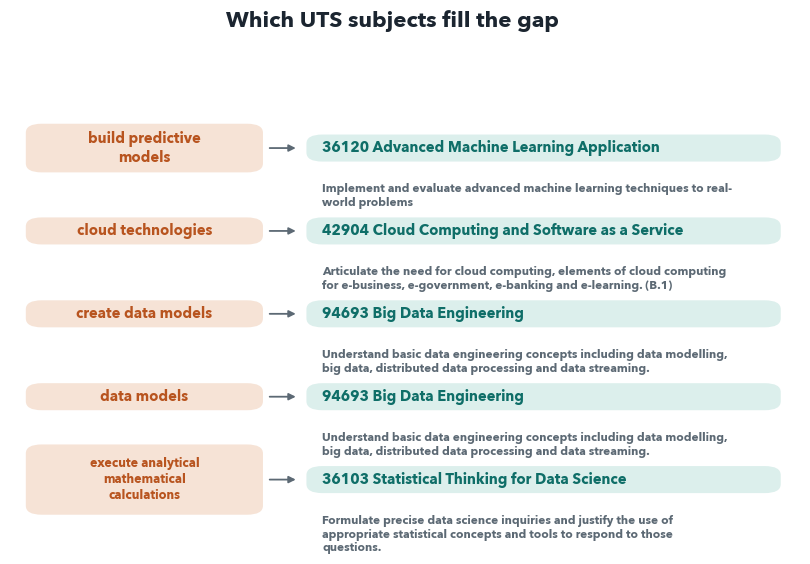

Saved course_table.png at 300dpi — drop this into the poster (block 7).


In [22]:
import textwrap

n_rows = max(len(course_rows), 1)
fig_h = max(2.4, 1.05 * n_rows + 0.6)
fig, ax = plt.subplots(figsize=(10.2, fig_h))
fig.patch.set_facecolor(SURFACE)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

fig.suptitle("Which UTS subjects fill the gap", fontsize=16, fontweight="bold",
             color=TEXT, y=1.0)

row_h = 0.92 / n_rows
top = 0.90

for i, (skill, subj, outcome) in enumerate(course_rows):
    y_c = top - i * row_h - row_h * 0.28

    skill_lines = textwrap.wrap(skill, width=18)
    skill_fontsize = 10.5 if len(skill_lines) <= 2 else 9
    chip_h = 0.03 + 0.024 * (len(skill_lines) - 1)
    ax.add_patch(mpatches.FancyBboxPatch((0.02, y_c - chip_h), 0.30, 2 * chip_h,
                 boxstyle="round,pad=0.0,rounding_size=0.02", linewidth=0,
                 facecolor=GAP_SOFT, transform=ax.transAxes))
    ax.text(0.17, y_c, "\n".join(skill_lines), ha="center", va="center",
            fontsize=skill_fontsize, fontweight="bold", color=COPPER,
            transform=ax.transAxes, linespacing=1.3)

    ax.annotate("", xy=(0.365, y_c), xytext=(0.325, y_c),
                xycoords="axes fraction", textcoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color=MUTED, linewidth=1.3))

    ax.add_patch(mpatches.FancyBboxPatch((0.375, y_c - 0.03), 0.60, 0.06,
                 boxstyle="round,pad=0.0,rounding_size=0.02", linewidth=0,
                 facecolor=ACCENT_SOFT, transform=ax.transAxes))
    ax.text(0.395, y_c, subj, ha="left", va="center", fontsize=10.5,
            fontweight="bold", color=TEAL, transform=ax.transAxes)

    wrapped = textwrap.fill(outcome, width=68)
    ax.text(0.395, y_c - row_h * 0.42, wrapped, ha="left", va="top", fontsize=8.5,
            color=MUTED, transform=ax.transAxes)

plt.savefig("course_table.png", dpi=300, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print("Saved course_table.png at 300dpi — drop this into the poster (block 7).")


## 9. Pipeline diagram — **poster block 4**

This is the actual diagram, not just the caption text — a 6-box flow matching the
team's style sheet (teal = data in/out, copper = the extraction/normalisation steps
this notebook implements, grey = the matching step, since that step gets compared
method-to-method rather than run once).

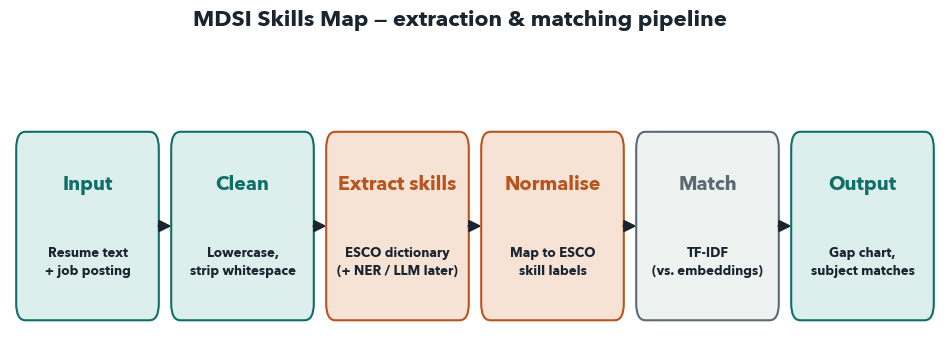

Saved pipeline_diagram.png at 300dpi — drop this into the poster (block 4).


In [23]:
stages = [
    ("Input", "Resume text\n+ job posting"),
    ("Clean", "Lowercase,\nstrip whitespace"),
    ("Extract skills", "ESCO dictionary\n(+ NER / LLM later)"),
    ("Normalise", "Map to ESCO\nskill labels"),
    ("Match", "TF-IDF\n(vs. embeddings)"),
    ("Output", "Gap chart,\nsubject matches"),
]
stage_ink = [TEAL, TEAL, COPPER, COPPER, MUTED, TEAL]
stage_fill = [ACCENT_SOFT, ACCENT_SOFT, GAP_SOFT, GAP_SOFT, SURFACE_2, ACCENT_SOFT]

fig, ax = plt.subplots(figsize=(12, 3.6))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
ax.axis("off")
ax.set_xlim(0, len(stages))
ax.set_ylim(0, 1)
box_w, box_h = 0.88, 0.64
y_center = 0.44

for i, (title, sub) in enumerate(stages):
    x = i + 0.5
    rect = mpatches.FancyBboxPatch(
        (x - box_w / 2, y_center - box_h / 2), box_w, box_h,
        boxstyle="round,pad=0.02,rounding_size=0.06",
        linewidth=1.5, edgecolor=stage_ink[i], facecolor=stage_fill[i],
    )
    ax.add_patch(rect)
    ax.text(x, y_center + 0.15, title, ha="center", va="center",
            fontsize=14, fontweight="bold", color=stage_ink[i])
    ax.text(x, y_center - 0.13, sub, ha="center", va="center",
            fontsize=9.5, color=TEXT, linespacing=1.5)
    if i < len(stages) - 1:
        arrow = FancyArrowPatch(
            (x + box_w / 2, y_center), (x + 1 - box_w / 2, y_center),
            arrowstyle="-|>", mutation_scale=18, color=TEXT, linewidth=1.5,
        )
        ax.add_patch(arrow)

fig.suptitle("MDSI Skills Map — extraction & matching pipeline", fontsize=16,
             fontweight="bold", color=TEXT, y=1.05)
plt.savefig("pipeline_diagram.png", dpi=300, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print("Saved pipeline_diagram.png at 300dpi — drop this into the poster (block 4).")


## 10. Poster caption text (within word budget)

These are just the short captions/blurbs that go *next to* the figures above —
block 4's diagram, block 6's chart, block 7's table. Edit before pasting, don't
use as-is.

In [24]:
print("BLOCK 4 — Pipeline (~40 words)")
print(
    "Input resume/job text -> clean -> extract skills via ESCO dictionary "
    "-> normalise to ESCO -> match via TF-IDF -> gap, suggested subjects."
)

print("\nBLOCK 6 — Preliminary results (~60 words)")
print(
    f"Comparing one sample resume to one real 'Data Scientist, Sydney' posting: "
    f"{len(matched)} of {len(job_skills)} required skills matched, {len(missing)} missing. "
    f"Top gaps: {', '.join(missing[:3])}."
)

print("\nBLOCK 7 — Which subjects fill the gap (~40 words)")
for skill, subj, outcome in course_rows[:3]:
    print(f"- {skill} -> {subj}")


BLOCK 4 — Pipeline (~40 words)
Input resume/job text -> clean -> extract skills via ESCO dictionary -> normalise to ESCO -> match via TF-IDF -> gap, suggested subjects.

BLOCK 6 — Preliminary results (~60 words)
Comparing one sample resume to one real 'Data Scientist, Sydney' posting: 3 of 14 required skills matched, 11 missing. Top gaps: build predictive models, cloud technologies, create data models.

BLOCK 7 — Which subjects fill the gap (~40 words)
- build predictive models -> 36120 Advanced Machine Learning Application
- cloud technologies -> 42904 Cloud Computing and Software as a Service
- create data models -> 94693 Big Data Engineering
